---

## Pre-Submission Checklist

- [ ] Name and student ID at top
- [ ] No cells are added or removed
- [ ] All TODO sections completed
- [ ] All questions answered
- [ ] Code runs without errors
- [ ] Results tables included
- [ ] Run All before saving

## Setup and Imports

In [1]:
!pip install gensim

# Standard libraries
import numpy as np
import pandas as pd
import random
from collections import defaultdict, Counter
import os

# Scikit-learn for TF-IDF and PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# Gensim for Word2Vec
from gensim.models import Word2Vec

# NLTK for preprocessing
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Matplotlib for PCA explained variance curve
import matplotlib.pyplot as plt

# Set random seed for reproducibility
seed = 42
np.random.seed(seed)
random.seed(seed)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 40.1 MB/s eta 0:00:00


---

# Task 1: Data Loading and Preprocessing (8 points)

Load the BBC News Dataset and apply standard preprocessing.

## 1.1: Load the BBC News Dataset (4 points)

Download the dataset and load all documents with their category labels.

In [2]:
# Download required NLTK data
nltk.download('punkt')
nltk.download('stopwords')

# Download BBC News Dataset
!wget -q http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip
!unzip -q bbc-fulltext.zip
documents = []
labels =[]

for path, folders, files in os.walk("bbc"):
  for filename in files:
    file_path = os.path.join(path, filename)
    with open(file_path, 'r') as f:
      documents.append(f.read())
      labels.append(os.path.basename(path))




# TODO: Load all documents from the BBC dataset
#
# Steps:
# 1. Navigate through the 'bbc' directory structure
# 2. For each category folder (business, entertainment, politics, sport, tech):
#    - Read all text files
#    - Store document text and category label
# 3. Create lists: documents (raw text) and labels (category names)
#
# Expected output:
# - documents: list of strings (raw document text)
# - labels: list of strings (category names)



print(f"Total documents loaded: {len(documents)}")
print(f"Categories: {set(labels)}")
print(f"\nCategory distribution:")
for cat in sorted(set(labels)):
    print(f"  {cat}: {labels.count(cat)}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Total documents loaded: 2226
Categories: {'bbc', 'entertainment', 'politics', 'sport', 'business', 'tech'}

Category distribution:
  bbc: 1
  business: 510
  entertainment: 386
  politics: 417
  sport: 511
  tech: 401


## 1.2: Preprocessing Function (2 points)

Implement a preprocessing function that applies tokenisation, lowercasing, and optional stopword removal.

In [3]:
nltk.download('punkt_tab')
def preprocess_text(text, remove_stopwords=False):
    """
    Preprocess text: tokenise, lowercase, and optionally remove stopwords.

    Args:
        text: Raw document text
        remove_stopwords: Whether to remove stopwords (default False)

    Returns:
        List of processed tokens
    """
    Tokizee = word_tokenize(text)

    tokens = []
    for t in Tokizee:
        tokens.append(t.lower())

    alph = []
    for a in tokens:
        if a.isalpha() == True:
            alph.append(a)
    if remove_stopwords:
        stop_words = set(stopwords.words('english'))
        alph = [t for t in alph if t not in stop_words]
    return alph
    # TODO: Implement preprocessing
    #
    # Steps:
    # 1. Tokenise using word_tokenize
    # 2. Convert to lowercase
    # 3. Keep only alphabetic tokens (use str.isalpha())
    # 4. If remove_stopwords is True, filter out stopwords
    # 5. Return list of processed tokens

    pass

# Test preprocessing
sample_text = "The quick brown fox jumps over the lazy dog!"
print("Original:", sample_text)
print("Processed:", preprocess_text(sample_text))
print("Without stopwords:", preprocess_text(sample_text, remove_stopwords=True))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original: The quick brown fox jumps over the lazy dog!
Processed: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Without stopwords: ['quick', 'brown', 'fox', 'jumps', 'lazy', 'dog']


## 1.3: Apply Preprocessing to All Documents (2 points)

Preprocess all documents and store both tokenised and string versions.

In [4]:
# TODO: Preprocess all documents

#
# Create two versions:
# 1. processed_docs: list of token lists (for Word2Vec)



# 2. processed_docs_str: list of strings (for TF-IDF)




# Use remove_stopwords=False for now

processed_docs = []

for doc in documents:
    tokens = preprocess_text(doc, remove_stopwords=False)
    processed_docs.append(tokens)
processed_docs_str = []

for tokens in processed_docs:
    doc_str = ' '.join(tokens)
    processed_docs_str.append(doc_str)


print(f"Preprocessed {len(processed_docs)} documents")
print(f"\nExample preprocessed document (first 20 tokens):")
print(processed_docs[0][:20])

Preprocessed 2226 documents

Example preprocessed document (first 20 tokens):
['consists', 'of', 'documents', 'from', 'the', 'bbc', 'news', 'website', 'corresponding', 'to', 'stories', 'in', 'five', 'topical', 'areas', 'from', 'natural', 'classes', 'business', 'entertainment']


---

# Task 2: Representation (8 points)

Build document representations using TF-IDF and Word2Vec.

## 2.1: Build TF-IDF Vectors (2 points)

Create TF-IDF document vectors using scikit-learn.

In [6]:
# TODO: Build TF-IDF representation
#
# Steps:
# 1. Initialise TfidfVectorizer with appropriate parameters:
#    - min_df: minimum document frequency (try 2 or 3)


#    - max_df: maximum document frequency (try 0.8 or 0.9)
#    - ngram_range: experiment with (1,1) or (1,2)
vectorizer  = TfidfVectorizer(min_df=3, max_df=0.9,ngram_range=(1,2))
tfidf_matrix  = vectorizer.fit_transform(processed_docs_str)
# 2. Fit and transform the processed_docs_str
# 3. Store the resulting matrix as tfidf_matrix
# 4. Print shape and number of features

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Number of features: {len(vectorizer.get_feature_names_out())}")

TF-IDF matrix shape: (2226, 58565)
Number of features: 58565


## 2.2: Train Word2Vec Model (2 points)

Train a Word2Vec model on the BBC News corpus.

In [25]:
# TODO: Train Word2Vec model
#
# Steps:
# 1. Initialise Word2Vec with parameters:
#    - vector_size: embedding dimension (try 100 or 200)
#    - window: context window size (try 5)
#    - min_count: minimum word frequency (try 2)
#    - sg: 0 for CBOW, 1 for Skip-gram (try both)
#    - seed: use seed variable for reproducibility
# 2. Train on processed_docs
# 3. Print vocabulary size

w2v_model = None  # YOUR CODE HERE

w2v_model = Word2Vec(sentences=processed_docs,vector_size=100,window=5, min_count=2,sg=1,seed=seed)
print(f"Word2Vec vocabulary size: {len(w2v_model.wv)}")
print(f"Vector dimension: {w2v_model.wv.vector_size}")

Word2Vec vocabulary size: 18295
Vector dimension: 100


## 2.3: Create Document Embeddings (4 points)

Aggregate word vectors to create document embeddings using simple averaging.

In [8]:
def create_doc_embedding(tokens, w2v_model):
    """
    Create document embedding by averaging word vectors.

    Args:
        tokens: List of tokens in document
        w2v_model: Trained Word2Vec model

    Returns:
        Document embedding vector (numpy array)
    """
    # TODO: Implement document embedding

    word_vectors = []

    for token in tokens:
        if token in w2v_model.wv:
            word_vectors.append(w2v_model.wv[token])

    if len(word_vectors) == 0:
        return np.zeros(w2v_model.wv.vector_size)

    return np.mean(word_vectors, axis=0)

    # Steps:
    # 1. Initialise empty list for word vectors
    # 2. For each token in the document:
    #    - If token is in model vocabulary, add its vector
    # 3. If no valid vectors found, return zero vector
    # 4. Otherwise, return mean of all word vectors

    pass

# TODO: Create document embeddings for all documents
doc_embeddings = []

for alp in processed_docs:
    empbeded = create_doc_embedding(alp, w2v_model)
    doc_embeddings.append(empbeded)

# Convert to numpy array
doc_embeddings = np.array(doc_embeddings)

print(f"Document embeddings shape: {doc_embeddings.shape}")

Document embeddings shape: (2226, 100)


---

# Task 3: Noise Injection (14 points)

Implement controlled noise injection to test representation robustness.

## 3.1: Random Token Deletion (4 points)

Implement random token deletion noise.

In [9]:
def apply_token_deletion(tokens, deletion_rate=0.1):
    """
    Randomly delete tokens from document.

    Args:
        tokens: List of tokens
        deletion_rate: Percentage of tokens to delete (default 0.1 = 10%)

    Returns:
        List of tokens after deletion
    """
    # TODO: Implement token deletion
    #
    # Steps:

    filtered_tokens=[]
    for token in tokens:

     num = random.random()
     if(num > deletion_rate):
      filtered_tokens.append(token)
    x=1
    if(len(filtered_tokens)==0) :
      for token in tokens:
       x=x+1

       filtered_tokens.append(token)
       if(x==2):
        break
    return filtered_tokens
    # 1. For each token, generate random number
    # 2. Keep token only if random number > deletion_rate
    # 3. Ensure at least one token remains
    # 4. Return filtered tokens

    pass

# Test token deletion
sample_tokens = preprocess_text("The quick brown fox jumps over the lazy dog")
print("Original:", sample_tokens)
print("10% deletion:", apply_token_deletion(sample_tokens, 0.1))
print("30% deletion:", apply_token_deletion(sample_tokens, 0.3))

Original: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
10% deletion: ['the', 'brown', 'fox', 'jumps', 'over', 'the', 'dog']
30% deletion: ['brown', 'over', 'the', 'dog']


## 3.2: Stopword Manipulation (3 points)

Implement stopword removal as another noise type.

In [10]:
def apply_stopword_removal(tokens):
    """
    Remove all stopwords from document.

    Args:
        tokens: List of tokens

    Returns:
        List of tokens without stopwords
    """
    # TODO: Implement stopword removal
    #

    filtered_tokens=[]
    a=0
    stop_words = set(stopwords.words('english'))
    for token in tokens:


     if token in stop_words:
      a=a+1
     else:
      filtered_tokens.append(token)
    if(len(filtered_tokens)==0) :
      for token in tokens:
       x=x+1

       filtered_tokens.append(token)
       if(x==2):
        break
    return filtered_tokens
    # Steps:
    # 1. Get English stopwords from NLTK
    # 2. Filter out tokens that are stopwords
    # 3. Ensure at least one token remains
    # 4. Return filtered tokens

    pass

# Test stopword removal
sample_tokens = preprocess_text("The quick brown fox jumps over the lazy dog")
print("Original:", sample_tokens)
print("Without stopwords:", apply_stopword_removal(sample_tokens))

Original: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Without stopwords: ['quick', 'brown', 'fox', 'jumps', 'lazy', 'dog']


## 3.3: Apply Noise to All Documents (7 points)

Create noisy versions of the dataset for evaluation.

In [11]:
# TODO: Create noisy versions of documents
#
# Create four versions:
# 1. noisy_docs_10: 10% token deletion
# 2. noisy_docs_20: 20% token deletion
# 3. noisy_docs_30: 30% token deletion
# 4. noisy_docs_stopword: stopword removal
#
# For each, store both token list and string versions

noisy_versions = {
    '10_del': {'tokens': [], 'strings': []},
    '20_del': {'tokens': [], 'strings': []},
    '30_del': {'tokens': [], 'strings': []},
    'stopword': {'tokens': [], 'strings': []}
}

# YOUR CODE HERE
for tokens in processed_docs:
  De_10 = apply_token_deletion(tokens, deletion_rate=0.1)
  De_20 = apply_token_deletion(tokens, deletion_rate=0.2)
  De_30 = apply_token_deletion(tokens, deletion_rate=0.3)
  stopword=apply_stopword_removal(tokens)
  noisy_versions['10_del']['tokens'].append(De_10)
  noisy_versions['10_del']['strings'].append(" ".join(De_10))
  noisy_versions['20_del']['tokens'].append(De_20)
  noisy_versions['20_del']['strings'].append(" ".join(De_20))
  noisy_versions['30_del']['tokens'].append(De_30)
  noisy_versions['30_del']['strings'].append(" ".join(De_30))
  noisy_versions['stopword']['tokens'].append(stopword)
  noisy_versions['stopword']['strings'].append(" ".join(stopword))
print("Noisy versions created:")
for name, data in noisy_versions.items():
    print(f"  {name}: {len(data['tokens'])} documents")


Noisy versions created:
  10_del: 2226 documents
  20_del: 2226 documents
  30_del: 2226 documents
  stopword: 2226 documents


---

# Task 4: PCA Dimensionality Reduction (20 points)

Apply PCA to reduce dimensionality of document representations.

TF-IDF 80% variance retained: 0.7919
TF-IDF 90% variance retained: 0.8943
Word Embeddings 80% variance retained: 0.8126
Word Embeddings 90% variance retained: 0.9019


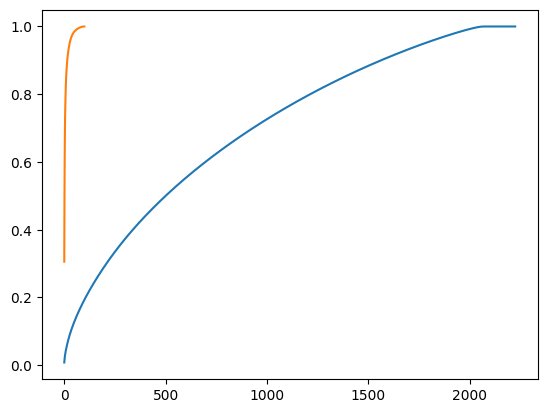

In [12]:
# TODO: PCA with variance-threshold–based dimensionality selection
tfidf = tfidf_matrix.toarray()

pca_full = PCA()
pca_full.fit(tfidf)
variance = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(variance)

x = 0
for var in variance:
    x += 1
    if var >= 0.8:
        break

y = 0
for var in variance:
    y += 1
    if var >= 0.9:
        break

pcatfidf_80 = PCA(n_components=x)
tfidf_pca_80 = pcatfidf_80.fit_transform(tfidf)
variance80_tfidf = np.sum(pcatfidf_80.explained_variance_ratio_)

pcatfidf_90 = PCA(n_components=y)
tfidf_pca_90 = pcatfidf_90.fit_transform(tfidf)
variance90_tfidf = np.sum(pcatfidf_90.explained_variance_ratio_)

print(f"TF-IDF 80% variance retained: {variance80_tfidf:.4f}")
print(f"TF-IDF 90% variance retained: {variance90_tfidf:.4f}")

X_w2v = doc_embeddings

pca_full = PCA()
pca_full.fit(X_w2v)
variance = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(variance)

x = 0
for var in variance:
    x += 1
    if var >= 0.8:
        break

y = 0
for var in variance:
    y += 1
    if var >= 0.9:
        break

pca_w2v_80_model = PCA(n_components=x)
w2v_pca_80 = pca_w2v_80_model.fit_transform(X_w2v)
variance80_w2v = np.sum(pca_w2v_80_model.explained_variance_ratio_)

pca_w2v_90_model = PCA(n_components=y)
w2v_pca_90 = pca_w2v_90_model.fit_transform(X_w2v)
variance90_w2v = np.sum(pca_w2v_90_model.explained_variance_ratio_)

print(f"Word Embeddings 80% variance retained: {variance80_w2v:.4f}")
print(f"Word Embeddings 90% variance retained: {variance90_w2v:.4f}")


# For each representation (TF-IDF and Word Embeddings):
# - Plot cumulative explained variance. (8 points)
# - Determine the minimum number of components required to retain
#   at least 80% and 90% of the variance. (4 points)
# - Apply PCA using these two dimensionalities. (4 points)
# - Report the exact value of explained variance and store the reduced representations. (4 points)


**Question 5.1:** How does PCA affect the information retained in TF-IDF compared to Word2Vec representations? Compare the number of components required to retain 80% and 90% of the variance. (2 point, 2-3 sentences)

**[Word Embeddings perform better than PCA. It preserves more variance compared to TF-IDF. Word Embeddings requires fewer components.]**

---

# Task 5: Information Retrieval System (20 points)

Build a cosine similarity-based retrieval system.

## 5.1: Define Queries (10 points)

Define 10-15 queries targeting different BBC News categories.

In [39]:
# TODO: Define queries
#
# Create a list of dictionaries with:
# - 'query': 2-5 content words
# - 'target_category': primary BBC News category
#
# Ensure queries cover all five categories

queries = [
    # Business queries
    {'query': 'stock market economy', 'target_category': 'business'},
    {'query': ' debt money interest', 'target_category': 'business'},
    {'query': 'film music dance', 'target_category': 'entertainment'},
    {'query': 'theater event show', 'target_category': 'entertainment'},
    {'query': 'football basketball referee', 'target_category': 'sport'},
    {'query': 'volleyball goal penalty', 'target_category': 'sport'},
    {'query': 'computer AI application', 'target_category': 'tech'},
    {'query': 'iphone car software', 'target_category': 'tech'},
    {'query': 'election government parliament', 'target_category': 'politics'},
    {'query': 'law, rally, constitution', 'target_category': 'politics'}


    # Add more queries here
    # YOUR CODE HERE
]

print(f"Total queries defined: {len(queries)}")
print("\nQueries by category:")
for cat in ['business', 'entertainment', 'politics', 'sport', 'tech']:
    count = sum(1 for q in queries if q['target_category'] == cat)
    print(f"  {cat}: {count}")

Total queries defined: 10

Queries by category:
  business: 2
  entertainment: 2
  politics: 2
  sport: 2
  tech: 2


## 5.2: Implement Retrieval Function 

Implement cosine similarity-based document retrieval.

In [40]:
def retrieve_documents(query_text, doc_vectors, vectorizer=None, w2v_model=None, top_k=10):
    """
    Retrieve top-k documents for a query using cosine similarity.

    Args:
        query_text: Query string
        doc_vectors: Document representation matrix
        vectorizer: TfidfVectorizer (if using TF-IDF)
        w2v_model: Word2Vec model (if using embeddings)
        top_k: Number of documents to retrieve

    Returns:
        List of document indices ranked by similarity
    """
    # TODO: Implement retrieval
    #
    # Steps:
    # 1. Preprocess query text


    if vectorizer is not None:
        q = vectorizer.transform([query_text]).toarray()


        if doc_vectors.shape[1] != q.shape[1]:
            if doc_vectors.shape[1] == pcatfidf_80.n_components:
                q = pcatfidf_80.transform(q)
            elif doc_vectors.shape[1] == pcatfidf_90.n_components:
                q = pcatfidf_90.transform(q)


        scores = cosine_similarity(q, doc_vectors).flatten()

    elif w2v_model is not None:
        tokens = preprocess_text(query_text)
        q = create_doc_embedding(tokens, w2v_model).reshape(1, -1)  # (1, D)


        if doc_vectors.shape[1] != q.shape[1]:
            if doc_vectors.shape[1] == pca_w2v_80_model.n_components:
                q = pca_w2v_80_model.transform(q)
            elif doc_vectors.shape[1] == pca_w2v_90_model.n_components:
                q = pca_w2v_90_model.transform(q)


        scores = cosine_similarity(q, doc_vectors).flatten()



    ranked_indices = np.argsort(scores)[::-1][:top_k]
    return ranked_indices.tolist()

    #    - If vectorizer: use vectorizer.transform
    #    - If w2v_model: use create_doc_embedding
    # 3. Compute cosine similarity with all documents
    # 4. Get top-k document indices by similarity
    # 5. Return ranked indices

    pass

---

# Task 6: Evaluation Metrics (20 points)

Implement and compute IR evaluation metrics.

## 6.1: Implement Evaluation Metrics (8 points)

Implement Precision@k, Recall@k, and MAP.

In [41]:
def precision_at_k(retrieved_docs, relevant_docs, k):
    """
    Calculate Precision@k.

    Args:
        retrieved_docs: List of retrieved document indices
        relevant_docs: Set of relevant document indices
        k: Number of top documents to consider

    Returns:
        Precision@k score
    """
    # TODO: Implement Precision@k
    pass

def recall_at_k(retrieved_docs, relevant_docs, k):
    """
    Calculate Recall@k.

    Args:
        retrieved_docs: List of retrieved document indices
        relevant_docs: Set of relevant document indices
        k: Number of top documents to consider

    Returns:
        Recall@k score
    """
    # TODO: Implement Recall@k
    count = 0
    top_k_docs=retrieved_docs[:k]
    for x in top_k_docs:
      if x in relevant_docs:

          count += 1


    return count/len(relevant_docs)
    pass

def average_precision(retrieved_docs, relevant_docs):
    """
    Calculate Average Precision.

    Args:
        retrieved_docs: List of retrieved document indices
        relevant_docs: Set of relevant document indices

    Returns:
        Average Precision score
    """
    # TODO: Implement Average Precision
    #
    # For each relevant document in retrieved list:
    # - Calculate precision at that position
    # - Average all precision values
    relevant = 0
    precisionsum = 0

    for i, doc_id in enumerate(retrieved_docs):
        if doc_id in relevant_docs:
            relevant+= 1
            precision = relevant / (i + 1)
            precisionsum += precision

    return precisionsum / len(relevant_docs)




    pass

def mean_average_precision(queries_results):
    """
    Calculate Mean Average Precision across all queries.

    Args:
        queries_results: List of (retrieved_docs, relevant_docs) tuples

    Returns:
        MAP score
    """
    # TODO: Implement MAP
    x= 0.0

    for retrieved_docs, relevant_docs in queries_results:
        x += average_precision(retrieved_docs, relevant_docs)

    return x/ len(queries_results)

    pass

## 6.2: Run Complete Evaluation 

Evaluate all representations (clean and noisy) using all metrics.

In [36]:
# TODO: Complete evaluation framework
#
# For each representation type:
# - TF-IDF (original, PCA-80%, PCA-90%)
# - Word Embeddings (original, PCA-80%, PCA-90%)
#
# For each noise condition:
# - Clean (no noise)
# - 10% deletion
# - 20% deletion
# - 30% deletion
# - Stopword removal
#
# For each query:
# - Retrieve top-10 documents
# - Identify relevant documents (same category)
# - Calculate Precision@5, Recall@5, AP
#
# Aggregate results and compute MAP
#
# Store results in structured format (e.g., DataFrame)

# YOUR CODE HERE
representations = {
    "tfidf_original": {"doc_vectors": tfidf_matrix,   "vectorizer": vectorizer, "w2v_model": None},
    "tfidf_pca_80":   {"doc_vectors": tfidf_pca_80,   "vectorizer": vectorizer, "w2v_model": None},
    "tfidf_pca_90":   {"doc_vectors": tfidf_pca_90,   "vectorizer": vectorizer, "w2v_model": None},
    "w2v_original":   {"doc_vectors": doc_embeddings, "vectorizer": None,       "w2v_model": w2v_model},
    "w2v_pca_80":     {"doc_vectors": w2v_pca_80,     "vectorizer": None,       "w2v_model": w2v_model},
    "w2v_pca_90":     {"doc_vectors": w2v_pca_90,     "vectorizer": None,       "w2v_model": w2v_model},
}




noise_conditions = ["clean", "10_del", "20_del", "30_del", "stopword"]
results = []
for rep_name, rep_data in representations.items():
    doc_vectors = rep_data["doc_vectors"]
    vec = rep_data["vectorizer"]
    w2v = rep_data["w2v_model"]

    for noise_name in noise_conditions:
        for q in queries:
            query_text = q["query"]
            target_category = q["target_category"]

            tokens = preprocess_text(query_text)

            if noise_name == "10_del":
                tokens = apply_token_deletion(tokens, 0.1)
            elif noise_name == "20_del":
                tokens = apply_token_deletion(tokens, 0.2)
            elif noise_name == "30_del":
                tokens = apply_token_deletion(tokens, 0.3)
            elif noise_name == "stopword":
                tokens = apply_stopword_removal(tokens)

            noisy_query = " ".join(tokens)

            retrieved_docs = retrieve_documents(noisy_query, doc_vectors, vectorizer=vec, w2v_model=w2v, top_k=10)
            relevant_docs = set()
            for i in range(len(labels)):
              if labels[i] == target_category:
                 relevant_docs.add(i)

            precision = precision_at_k(retrieved_docs, relevant_docs, 5)
            recall = recall_at_k(retrieved_docs, relevant_docs, 5)
            ap = average_precision(retrieved_docs, relevant_docs)

            results.append({ "representation": rep_name, "noise": noise_name, "query": query_text, "category": target_category,
                "precision": precision,
                "recall": recall,
                "AP": ap
            })

df_results = pd.DataFrame(results)

map_table = ( df_results.groupby(["representation", "noise"])["AP"].mean() .reset_index().rename(columns={"AP": "MAP"}))

pivot_map = map_table.pivot(index="representation",columns="noise",values="MAP")


print("="*80)
print("EVALUATION RESULTS")
print("="*80)
# Display your results here
print("="*80)
print("MAP TABLE")
print("="*80)
print(pivot_map.round(4))


EVALUATION RESULTS
MAP TABLE
noise           10_del  20_del  30_del   clean  stopword
representation                                          
tfidf_original  0.0156  0.0174  0.0171  0.0184    0.0184
tfidf_pca_80    0.0185  0.0132  0.0189  0.0185    0.0185
tfidf_pca_90    0.0195  0.0190  0.0167  0.0189    0.0189
w2v_original    0.0190  0.0180  0.0149  0.0203    0.0203
w2v_pca_80      0.0197  0.0158  0.0175  0.0197    0.0197
w2v_pca_90      0.0191  0.0180  0.0156  0.0189    0.0189


## 6.3: Analysis Questions

Answer the following questions based on your results.

---

# Convert Your Colab Notebook to PDF

### Step 1: Download Your Notebook
- Go to **File → Download → Download .ipynb**
- Save the file to your computer

### Step 2: Upload to Colab
- Click the **📁 folder icon** on the left sidebar
- Click the **upload button**
- Select your downloaded .ipynb file
- Wait for the upload to complete

### Step 3: Run the Code Below
- **Uncomment the cell below** and run the cell
- This will take about 1-2 minutes to install required packages

### Step 4: Enter Notebook Name
- When prompted, type your notebook name (e.g. `gs_000000_as4.ipynb`)
- Press Enter

### The PDF will automatically download to your computer

In [37]:
 # Install required packages (this takes about 30 seconds)
print("Installing PDF converter... please wait...")
!apt-get update -qq
!apt-get install -y texlive-xetex texlive-fonts-recommended texlive-plain-generic pandoc > /dev/null 2>&1
!pip install -q nbconvert

print("\n" + "="*50)
print("COLAB NOTEBOOK TO PDF CONVERTER")
print("="*50)
print("\nSTEP 1: Download your notebook")
print("- Go to File → Download → Download .ipynb")
print("- Save it to your computer")
print("\nSTEP 2: Upload it here")
print("- Click the folder icon on the left (📁)")
print("- Click the upload button and select your .ipynb file")
print("- Wait for upload to complete")
print("\nSTEP 3: Enter the filename below")
print("="*50)

#  Get notebook name from user
notebook_name = input("\nEnter your notebook name: ")

#  Add .ipynb if missing
if not notebook_name.endswith('.ipynb'):
     notebook_name += '.ipynb'

import os
notebook_path = f'/content/{notebook_name}'

# Check if file exists
if not os.path.exists(notebook_path):
     print(f"\n⚠ Error: '{notebook_name}' not found in /content/")
     print("\nMake sure you uploaded the file using the folder icon (📁) on the left!")
else:
     print(f"\n✓ Found {notebook_name}")
     print("Converting to PDF... this may take 1-2 minutes...\n")

     # Convert the notebook to PDF
     !jupyter nbconvert --to pdf "{notebook_path}"

     # Download the PDF
     from google.colab import files
     pdf_name = notebook_name.replace('.ipynb', '.pdf')
     pdf_path = f'/content/{pdf_name}'

     if os.path.exists(pdf_path):
         print("✓ SUCCESS! Downloading your PDF now...")
         files.download(pdf_path)
         print("\n✓ Done! Check your downloads folder.")
     else:
         print("⚠ Error: Could not create PDF")

Installing PDF converter... please wait...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)

COLAB NOTEBOOK TO PDF CONVERTER

STEP 1: Download your notebook
- Go to File → Download → Download .ipynb
- Save it to your computer

STEP 2: Upload it here
- Click the folder icon on the left (📁)
- Click the upload button and select your .ipynb file
- Wait for upload to complete

STEP 3: Enter the filename below

Enter your notebook name: 2526622_As4.ipynb

✓ Found 2526622_As4.ipynb
Converting to PDF... this may take 1-2 minutes...

[NbConvertApp] Converting notebook /content/2526622_As4.ipynb to pdf
[NbConvertApp] Support files will be in 2526622_As4_files/
[NbConvertApp] Making directory ./2526622_As4_files
[NbConvertApp] Writing 104219 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Done! Check your downloads folder.
